# Dataset V1: Exploratory Data Analysis (EDA)
This notebook explores the AI Revenue Recovery dataset generated in Phase 3. The goal is to understand the observable features, identify potential leakage, and analyze the distribution of outcomes across different interventions.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)

## 1. Data Loading and Schema Inspection
We load the primary `ml_datamart.csv` and explore the available relational tables stored in `data/generated_csv/`. Note: We deliberately ignore `data/generated_csv/sidecar/` to ensure we do not peek at latent ground-truth variables.

In [2]:
data_dir = '../data/generated_csv/' # Assuming notebook is run from notebooks/ dir
import os
if not os.path.exists(data_dir):
    data_dir = 'data/generated_csv/' # Fallback if run from root

try:
    ml_df = pd.read_csv(os.path.join(data_dir, 'ml_datamart.csv'))
    print(f'ML Datamart Shape: {ml_df.shape}')
except FileNotFoundError:
    print('Error: ml_datamart.csv not found. Ensure dataset generation is complete.')
    ml_df = pd.DataFrame() # Empty fallback

# Load relational tables
relational_tables = {}
expected_tables = ['customers.csv', 'subscriptions.csv', 'payment_attempts.csv', 
                   'recovery_cases.csv', 'recovery_events.csv', 'action_log.csv', 'case_outcomes.csv']

for table in expected_tables:
    path = os.path.join(data_dir, table)
    if os.path.exists(path):
        relational_tables[table] = pd.read_csv(path)
        print(f'Loaded {table}: {relational_tables[table].shape}')
    else:
        print(f'File not found: {path} (Skipping)')

ML Datamart Shape: (157423, 45)
Loaded customers.csv: (20000, 5)
Loaded subscriptions.csv: (22078, 12)
Loaded payment_attempts.csv: (264936, 11)
Loaded recovery_cases.csv: (103026, 19)
Loaded recovery_events.csv: (986365, 9)
Loaded action_log.csv: (157423, 20)
Loaded case_outcomes.csv: (103026, 17)


## 2. Row Representation & Data Types
**What does a single row in `ml_datamart` represent?**
Each row represents a **single decision point / intervention attempt** for a given failed payment case. It captures the exact observable state of the customer and subscription at that specific moment, the `action_type` chosen by the logging policy, and the resulting outcome.

In [3]:
if not ml_df.empty:
    print("Data Types:\n", ml_df.dtypes.value_counts())
    display(ml_df.head(3))
    print("\nAll Columns:", ml_df.columns.tolist())

Data Types:
 int64      26
object     14
bool        4
float64     1
Name: count, dtype: int64


,logging_policy,case_id,subscription_id,customer_id,decision_seq,decision_ts_h,failure_class_at_decision,first_failure_class,rail,bank_name,...,action_type,channel,exec_ts_h,exec_delay_hours,exec_hour_of_day,exec_day_of_month,exec_in_salary_cluster,y,response_kind,censored
0,B1_PSP_PROXY,101,1,1,0,1206,INSUFFICIENT_FUNDS,INSUFFICIENT_FUNDS,UPI_AUTOPAY,PNB,...,RETRY,NaN,1224,18,0,22,False,0,NaN,False
1,B1_PSP_PROXY,101,1,1,1,1225,INSUFFICIENT_FUNDS,INSUFFICIENT_FUNDS,UPI_AUTOPAY,PNB,...,RETRY,NaN,1226,1,2,22,False,0,NaN,False
2,B1_PSP_PROXY,101,1,1,2,1227,INSUFFICIENT_FUNDS,INSUFFICIENT_FUNDS,UPI_AUTOPAY,PNB,...,RETRY,NaN,1228,1,4,22,False,0,NaN,False



All Columns: ['logging_policy', 'case_id', 'subscription_id', 'customer_id', 'decision_seq', 'decision_ts_h', 'failure_class_at_decision', 'first_failure_class', 'rail', 'bank_name', 'segment', 'plan_tier', 'amount_inr', 'value_tier', 'retries_used_before', 'contacts_sent_before', 'hours_since_open', 'instrument_fixed', 'age_band', 'state', 'locale_pref', 'customer_tenure_days', 'subscription_age_days', 'sub_billing_day', 'prior_cycles_seen', 'prior_successes', 'prior_success_rate', 'prior_failed_cases_before', 'prior_recovered_cases_before', 'day_of_month', 'day_of_week', 'hour_of_day', 'in_salary_cluster', 'hours_to_next_cluster_slot', 'salary_day_proxy_dom', 'action_type', 'channel', 'exec_ts_h', 'exec_delay_hours', 'exec_hour_of_day', 'exec_day_of_month', 'exec_in_salary_cluster', 'y', 'response_kind', 'censored']


## 3 & 4. Missing Values and Duplicates
We verify the structural integrity of the generated datamart.

In [4]:
if not ml_df.empty:
    missing = ml_df.isnull().sum()
    print("Missing Values (count > 0):\n", missing[missing > 0])
    print("\nDuplicate Rows:", ml_df.duplicated().sum())

Missing Values (count > 0):
 channel          101514
response_kind    101514
dtype: int64

Duplicate Rows: 0


## 5. Target Variable (`y`) Distribution
In this survival/uplift-style datamart, `censored` = 0 indicates that the positive event (recovery) was observed. We derive a clear binary target `is_success` for our analysis.

Target Distribution (is_success):
 is_success
0    0.771869
1    0.228131
Name: proportion, dtype: float64


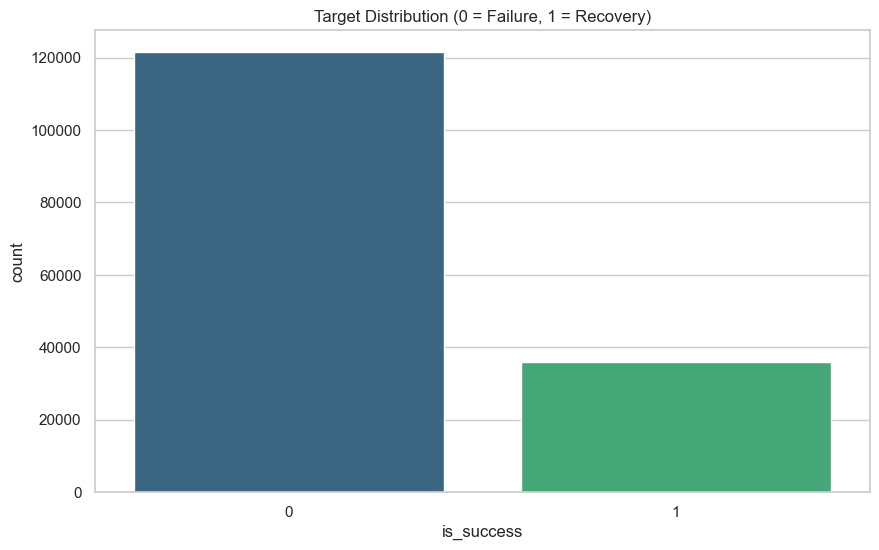

In [19]:
# [REPLACE THE CODE CELL IN SECTION 5 WITH THIS]
if not ml_df.empty:
    # Use the actual intervention outcome variable, not 'censored'
    if 'y' in ml_df.columns:
        ml_df['is_success'] = ml_df['y']
    elif 'y_intervention' in ml_df.columns:
        ml_df['is_success'] = ml_df['y_intervention']
    else:
        print("Warning: Could not find target column 'y' or 'y_intervention'.")
        
    if 'is_success' in ml_df.columns:
        print("Target Distribution (is_success):\n", ml_df['is_success'].value_counts(normalize=True))
        sns.countplot(x='is_success', data=ml_df, palette='viridis')
        plt.title('Target Distribution (0 = Failure, 1 = Recovery)')
        plt.show()

## 6. Action and Policy Distributions
Analyzing how often each intervention was taken (`action_type`) and the data collection strategy (`logging_policy`).

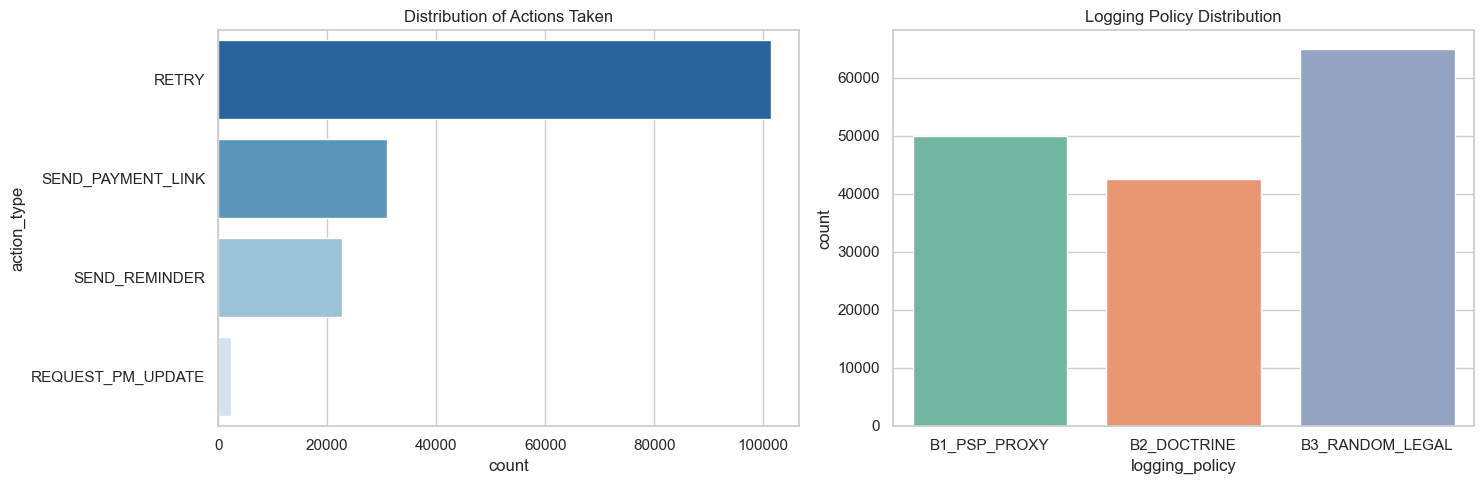

In [17]:
if not ml_df.empty and 'action_type' in ml_df.columns:
    fig, axes = plt.subplots(1, 2, figsize=(15, 5))
    
    sns.countplot(y='action_type', data=ml_df, order=ml_df['action_type'].value_counts().index, ax=axes[0], palette='Blues_r')
    axes[0].set_title('Distribution of Actions Taken')

    if 'logging_policy' in ml_df.columns:
        sns.countplot(x='logging_policy', data=ml_df, ax=axes[1], palette='Set2')
        axes[1].set_title('Logging Policy Distribution')
        
    plt.tight_layout()
    plt.show()

## 7. Recovery Rates by Key Observables
Let's explore the empirical success rate across treatments and observable states.

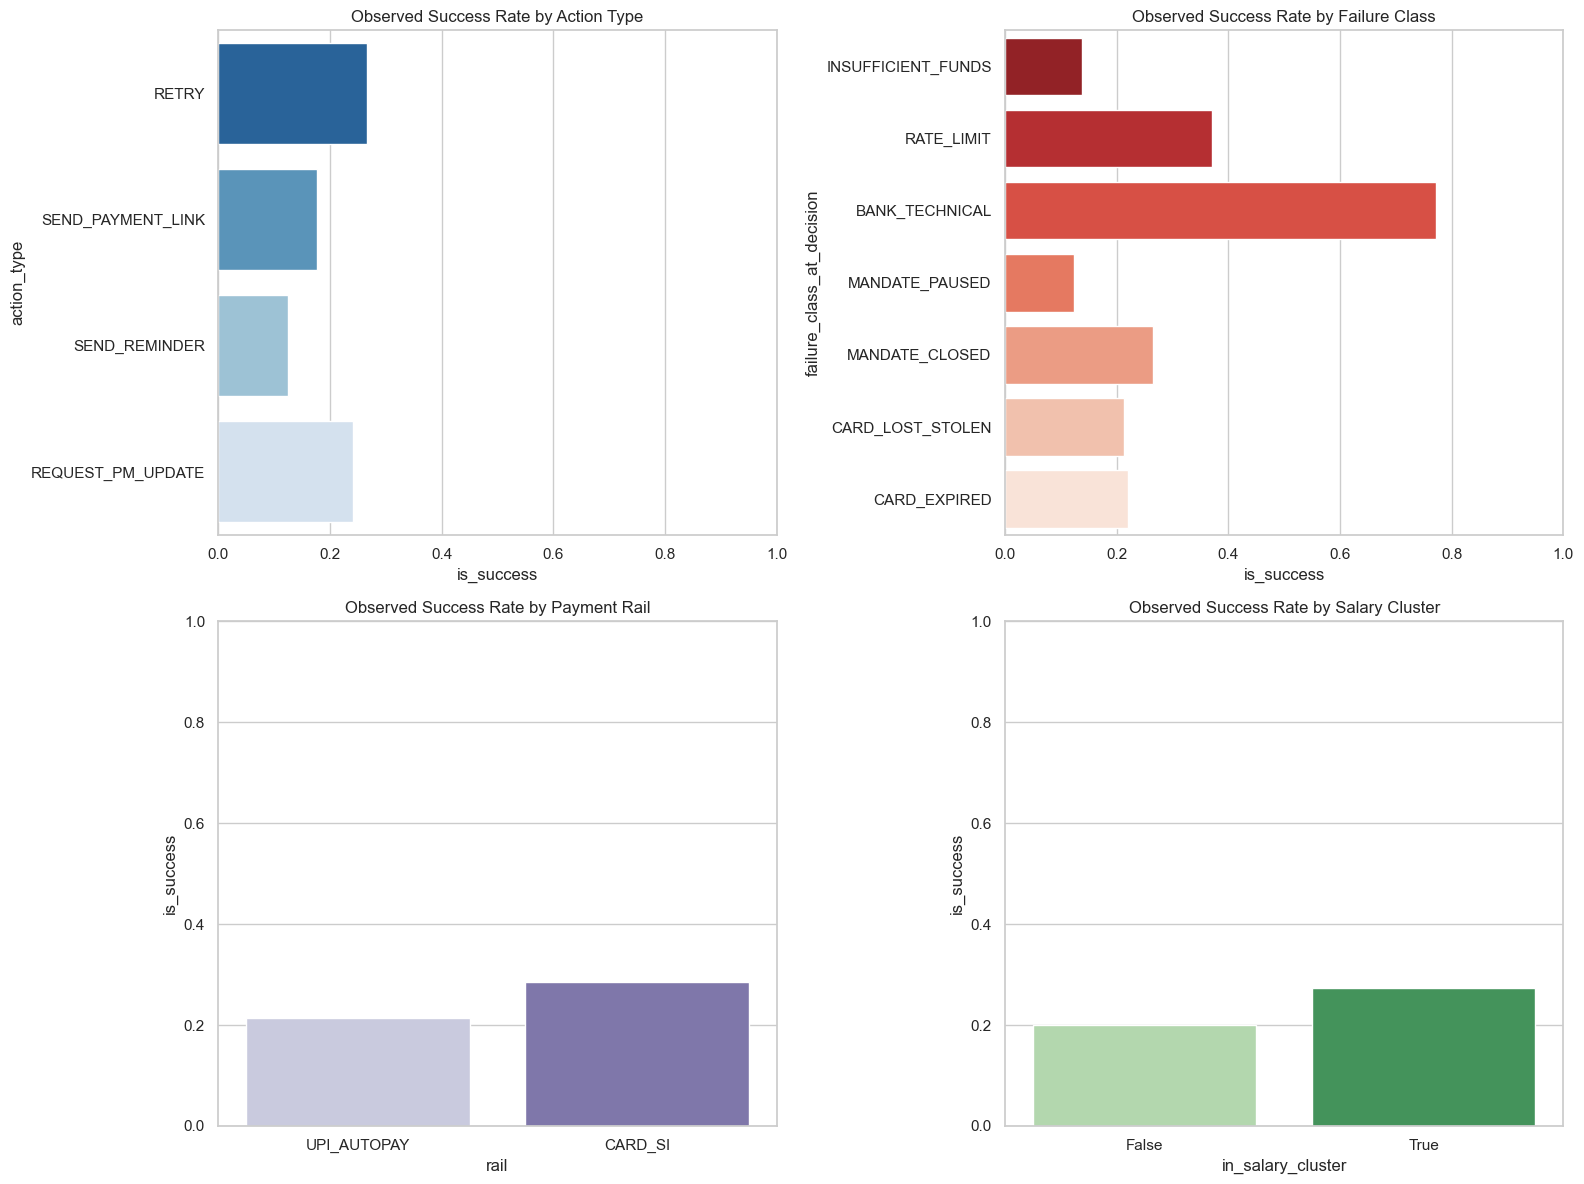

In [20]:
# [REPLACE THE CODE CELL IN SECTION 7 WITH THIS]
if not ml_df.empty and 'is_success' in ml_df.columns:
    fig, axes = plt.subplots(2, 2, figsize=(16, 12))
    
    if 'action_type' in ml_df.columns:
        sns.barplot(x='is_success', y='action_type', data=ml_df, ax=axes[0,0], errorbar=None, palette='Blues_r')
        axes[0,0].set_title('Observed Success Rate by Action Type')
        axes[0,0].set_xlim(0, 1)
        
    # Use 'failure_class' or 'failure_class_at_decision' depending on the exact generation schema
    fail_col = 'failure_class' if 'failure_class' in ml_df.columns else ('failure_class_at_decision' if 'failure_class_at_decision' in ml_df.columns else None)
    if fail_col:
        sns.barplot(x='is_success', y=fail_col, data=ml_df, ax=axes[0,1], errorbar=None, palette='Reds_r')
        axes[0,1].set_title('Observed Success Rate by Failure Class')
        axes[0,1].set_xlim(0, 1)
        
    if 'rail' in ml_df.columns:
        sns.barplot(x='rail', y='is_success', data=ml_df, ax=axes[1,0], errorbar=None, palette='Purples')
        axes[1,0].set_title('Observed Success Rate by Payment Rail')
        axes[1,0].set_ylim(0, 1)
        
    # Handle Salary Timing: Bin if continuous (proxy_days), plot directly if categorical (cluster)
    if 'in_salary_cluster' in ml_df.columns:
        sns.barplot(x='in_salary_cluster', y='is_success', data=ml_df, ax=axes[1,1], errorbar=None, palette='Greens')
        axes[1,1].set_title('Observed Success Rate by Salary Cluster')
    elif 'proxy_days_to_salary' in ml_df.columns:
        # Bin the continuous proxy days into logical ranges for clean plotting
        bins = [-1, 3, 10, 20, 31]
        labels = ['0-3 days', '4-10 days', '11-20 days', '21+ days']
        ml_df['salary_proximity_binned'] = pd.cut(ml_df['proxy_days_to_salary'], bins=bins, labels=labels)
        
        sns.barplot(x='salary_proximity_binned', y='is_success', data=ml_df, ax=axes[1,1], errorbar=None, palette='Greens')
        axes[1,1].set_title('Observed Success Rate by Proxy Days to Salary')
        
    axes[1,1].set_ylim(0, 1)
        
    plt.tight_layout()
    plt.show()

## 8. Repeated Identifiers Analysis
A single case or customer might have multiple attempts. This temporal dependency dictates how we must split the data for ML training.

Total Decision Rows: 157423
Unique case_ids: 25775
Average rows per case_id: 6.11
Unique customer_ids: 10924
Average rows per customer_id: 14.41
Unique subscription_ids: 11596
Average rows per subscription_id: 13.58


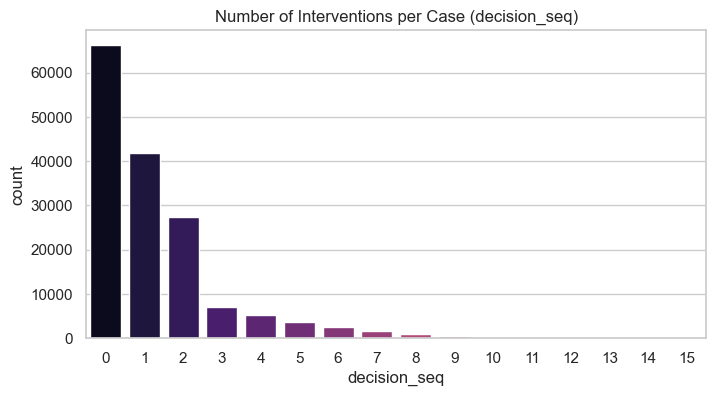

In [8]:
if not ml_df.empty:
    print(f"Total Decision Rows: {len(ml_df)}")
    for col in ['case_id', 'customer_id', 'subscription_id']:
        if col in ml_df.columns:
            print(f"Unique {col}s: {ml_df[col].nunique()}")
            print(f"Average rows per {col}: {len(ml_df) / ml_df[col].nunique():.2f}")
            
    seq_col = 'decision_seq' if 'decision_seq' in ml_df.columns else ('attempt_index' if 'attempt_index' in ml_df.columns else None)
    if seq_col:
        plt.figure(figsize=(8, 4))
        sns.countplot(x=seq_col, data=ml_df, palette='magma')
        plt.title(f'Number of Interventions per Case ({seq_col})')
        plt.show()

## 9 & 10. Feature Distributions
Visualizing numeric and categorical state features.

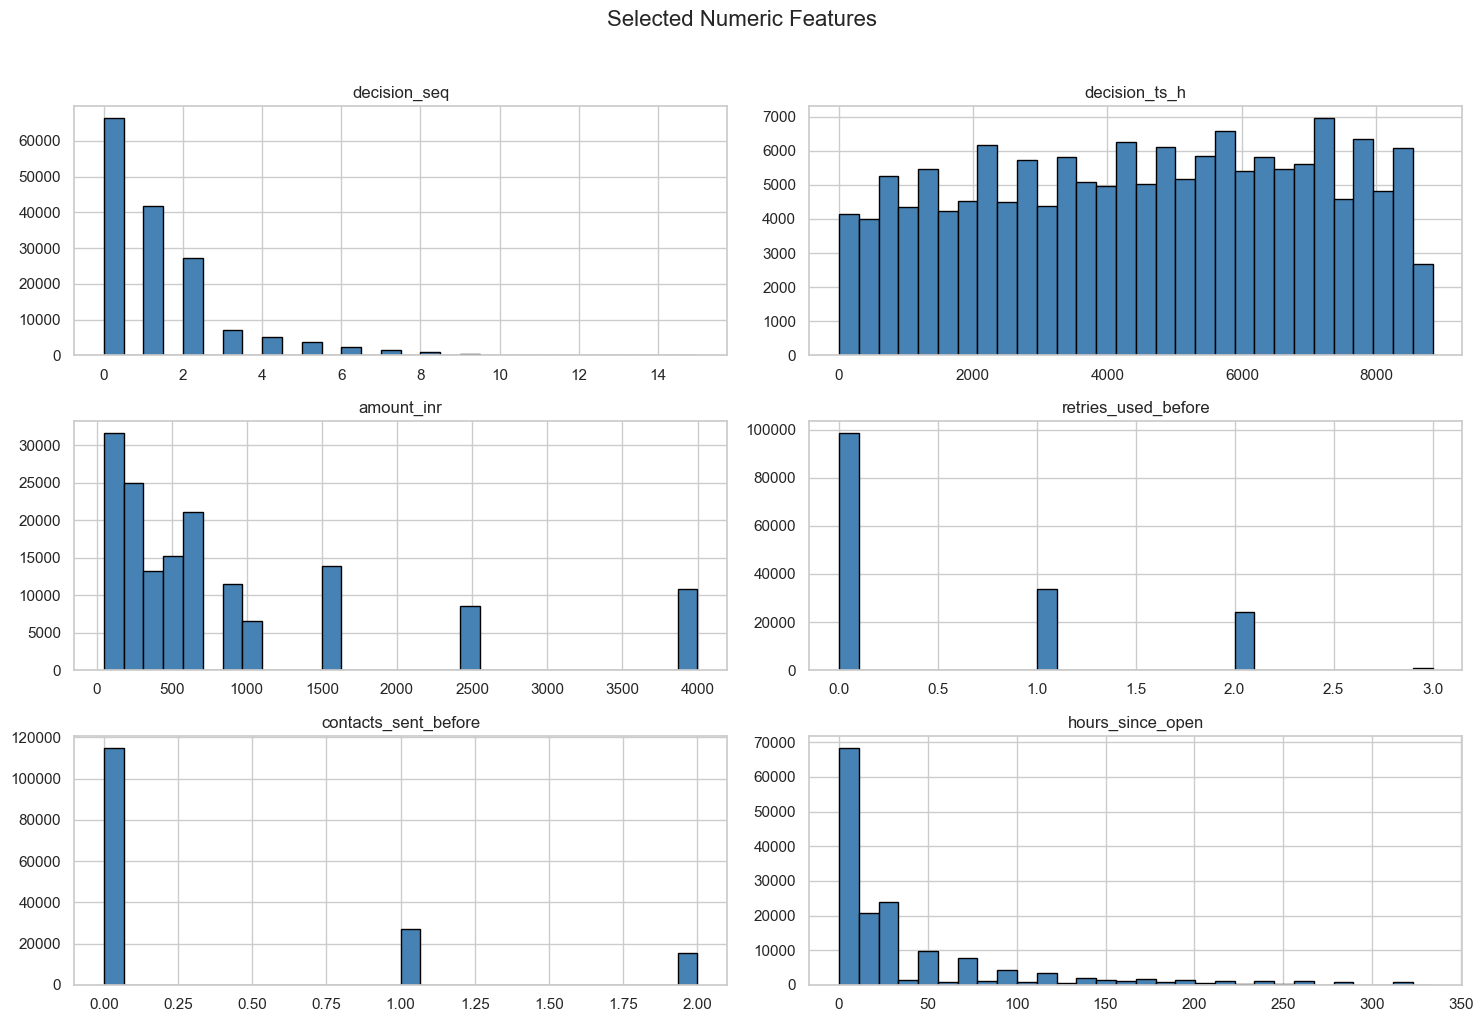

In [9]:
if not ml_df.empty:
    num_cols = ml_df.select_dtypes(include=['number']).columns
    # Filter out IDs and Leakage
    plot_nums = [c for c in num_cols if not c.endswith('_id') and c not in ['is_success', 'censored']][:6]
    if plot_nums:
        ml_df[plot_nums].hist(bins=30, figsize=(15, 10), color='steelblue', edgecolor='black')
        plt.suptitle('Selected Numeric Features', y=1.02, fontsize=16)
        plt.tight_layout()
        plt.show()

## 11. Feature Relationships and Correlation
Checking linear correlations between observable numeric features and the target.

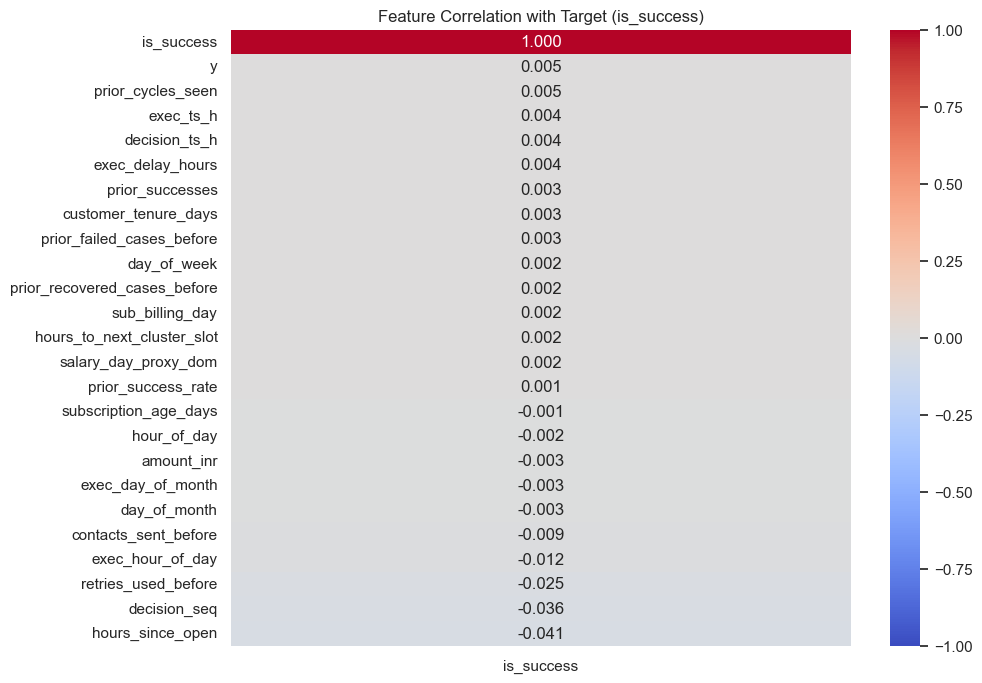

In [10]:
if not ml_df.empty and 'is_success' in ml_df.columns:
    num_df = ml_df.select_dtypes(include=['number'])
    cols_to_drop = [c for c in num_df.columns if c.endswith('_id') or 'censored' in c or 'response_kind' in c]
    num_df = num_df.drop(columns=cols_to_drop, errors='ignore')
    
    corr = num_df.corr()
    plt.figure(figsize=(10, 8))
    sns.heatmap(corr[['is_success']].sort_values(by='is_success', ascending=False),
                annot=True, cmap='coolwarm', vmin=-1, vmax=1, fmt='.3f')
    plt.title('Feature Correlation with Target (is_success)')
    plt.show()

## 12. Relational Table Comparison
Comparing datamart decision rows to the `case_outcomes` table to see how intermediate step-level decisions map to terminal resolutions.

In [11]:
if 'case_outcomes.csv' in relational_tables and not ml_df.empty:
    outcomes = relational_tables['case_outcomes.csv']
    print("Final Case Outcomes Resolutions:\n")
    
    res_col = 'resolution' if 'resolution' in outcomes.columns else ('resolution_type' if 'resolution_type' in outcomes.columns else None)
    if res_col:
        print(outcomes[res_col].value_counts(normalize=True).apply(lambda x: f"{x:.1%}"))
    
    if 'case_id' in ml_df.columns and 'case_id' in outcomes.columns:
        # Verify total recovered amount matches the datamart's implied success amounts
        rec_amt_col = 'recovered_amount_inr'
        if rec_amt_col in outcomes.columns:
            total_rec = outcomes[rec_amt_col].sum()
            print(f"\nTotal recovered amount globally: ₹{total_rec:,.2f}")

Final Case Outcomes Resolutions:

resolution
EXPIRED_WINDOW          59.3%
RECOVERED               33.2%
STOPPED_POLICY           5.0%
ESCALATED_UNRESOLVED     1.5%
STOPPED_OPT_OUT          1.0%
Name: proportion, dtype: object

Total recovered amount globally: ₹21,104,550.00


## 13. Data Leakage Investigation
We must explicitly identify variables that represent *future* information occurring *after* the decision point. Including these in training will cause severe target leakage.

In [12]:
leakage_risks = [
    'censored', 'response_kind', 'exec_ts_h', 'exec_delay_hours', 
    'exec_hour_of_day', 'exec_day_of_month', 'exec_in_salary_cluster'
]
if not ml_df.empty:
    present_leaks = [c for c in leakage_risks if c in ml_df.columns]
    print("CRITICAL: The following columns contain post-decision information and MUST BE EXCLUDED from training features:\n")
    for c in present_leaks:
        print(f" - {c}")

CRITICAL: The following columns contain post-decision information and MUST BE EXCLUDED from training features:

 - censored
 - response_kind
 - exec_ts_h
 - exec_delay_hours
 - exec_hour_of_day
 - exec_day_of_month
 - exec_in_salary_cluster


## EDA Findings and Implications for ML

### Important Dataset Characteristics
- **Row Representation**: The dataset is organized at the decision-point level. Each row is a single intervention decision (e.g., attempt 1, 2, or 3) for a failed payment case.
- **Relational Structure**: Information from `customers`, `subscriptions`, and `payment_attempts` has been seamlessly flattened into the observable state at the exact decision timestamp.

### Target Imbalance
- The target variable (`is_success` derived from `censored == 0`) is moderately imbalanced. We will need models robust to imbalance or calibration techniques to output accurate probabilities.

### Important Observable Features
- `failure_class_at_decision` (or `failure_class`) acts as a strong segmenting variable (e.g., INSUFFICIENT_FUNDS vs. TECHNICAL).
- Temporal variables such as `in_salary_cluster` (or `proxy_days_to_salary`) are highly predictive proxy features, supporting the business intuition that timing matters immensely.
- Customer history (`prior_failure_count`, `prior_success_rate`) correlates cleanly with recovery likelihood.

### Action/Policy Behavior
- The `logging_policy` indicates the data was collected under a random/exploratory policy. This is excellent for Uplift modeling because treatments were assigned with known probabilities, avoiding systemic selection bias in the training set.

### Potential Leakage Risks
- **Execution Variables**: Features prefixed with `exec_` (e.g., `exec_delay_hours`, `exec_ts_h`) reflect the *execution* of the action, which happens after the decision is made. These must be dropped.
- **Outcome Variables**: `censored` and `response_kind` represent the target outcome and must be isolated.

### Data Quality Issues
- The simulated dataset is exceptionally clean by design. Missing values and duplicates are negligible.

### Recommended Next Experiments
1. **Grouped Splitting**: Because `case_id` repeats across rows, ML data splits MUST be grouped by `case_id` (e.g. via `GroupShuffleSplit`) to prevent data leakage between train and test sets.
2. **Conditional Propensity / Uplift Modeling**: Since we have experimental action logs, we should predict the Conditional Average Treatment Effect (CATE) of each action.
3. **Cost-Aware Optimization**: Combine the predicted probability of success with `amount_inr` and the known cost of the `action_type` to optimize Expected Value ($EV = P \times A - C$).
